** DATA LOADING & MISSING VALUE IMPUTATION **

 Load dataset from CSV into a pandas DataFrame and display initial rows

In [ ]:
import numpy as np
import pandas as pd
df=pd.read_csv("/content/vehicle_sales_dirty.csv")
df

,Car_ID,Brand,Model_Year,Fuel_Type,Transmission,Seller_Type,Owner,Driven_KMs,Engine_CC,Mileage_kmpl,Selling_Price,Present_Price,Brand_dup,Selling_Price_dup
0,136,Mahindra,2019,diesel,Manual,dealer,First,149797,1547,27.47,2468431.0,328799,Mahindra,2468431.0
1,172,ford,2007,Diesel,auto,Individual,Second,198712,1085,28.03,190619.0,510679,ford,190619.0
2,223,Toyota,2012,diesel,manual,Individual,Third,177021,3005,18.80,563201.0,2848833,Toyota,563201.0
3,73,Honda,2002,NaN,Automatic,Dealer,First,54828,1640,27.58,2271388.0,1459276,Honda,2271388.0
4,152,Tata,2010,diesel,Manual,Dealer,NaN,128515,2281,25.85,1806288.0,1720392,Tata,1806288.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
280,77,Toyota,2014,Hybrid,auto,Dealer,Second,137252,1644,12.43,679796.0,2470387,Toyota,679796.0
281,104,Mercedes,2004,diesel,Automatic,Individual,Third,128428,3129,22.36,686338.0,2044183,Mercedes,686338.0
282,195,Toyota,2018,Electric,NaN,Dealer,3rd,139250,3145,13.26,2409904.0,2883890,Toyota,2409904.0
283,66,ford,2000,Diesel,auto,Individual,2nd,79217,1928,17.52,1423317.0,449891,ford,1423317.0


Check dataset structure, column data types, memory usage, and missing values

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 285 entries, 0 to 284
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Car_ID             285 non-null    int64  
 1   Brand              263 non-null    object 
 2   Model_Year         285 non-null    int64  
 3   Fuel_Type          223 non-null    object 
 4   Transmission       204 non-null    object 
 5   Seller_Type        285 non-null    object 
 6   Owner              251 non-null    object 
 7   Driven_KMs         285 non-null    int64  
 8   Engine_CC          285 non-null    int64  
 9   Mileage_kmpl       285 non-null    float64
 10  Selling_Price      262 non-null    float64
 11  Present_Price      285 non-null    int64  
 12  Brand_dup          263 non-null    object 
 13  Selling_Price_dup  262 non-null    float64
dtypes: float64(3), int64(5), object(6)
memory usage: 31.3+ KB


Inspect unique values in Selling_Price to check for missing values or irregularities

In [ ]:
df["Selling_Price"].unique()

array([2468431.,  190619.,  563201., 2271388., 1806288., 1309821.,
        987565.,  680462., 1566368., 2231659.,  826034., 2131225.,
       2227513., 2383184.,  598421.,  833271., 1238902., 1195453.,
       1247611.,      nan, 2483143., 1235539., 1518274., 2193520.,
       2071860., 1160774., 2320394., 1292885., 1526067., 2074499.,
       1423929.,  877130., 2418483.,  115985., 2484356., 1007853.,
        726833.,  181469., 1178087., 1043503.,  304663., 1009798.,
       2274092., 1769697.,  241037., 1137934., 1957665., 1774728.,
       1952860., 1880643., 1530762.,  153430., 2243313.,  272102.,
       1322137., 1652229.,  331973., 1427608.,  754824.,  174963.,
       2401832., 2331283., 1703716.,  879103., 1120067.,  950651.,
       1894596.,  676567.,  232229., 1476364., 1211069.,  857680.,
        191494.,  112133., 1978006., 1349691., 2392084.,  965666.,
       2447089., 1757872., 2168079., 1360054., 1491735., 1158835.,
       1533048.,  810759.,  825526., 1802860., 1121951., 14132

Impute missing values in Selling_Price using the column mean

In [ ]:
df["Selling_Price"].fillna(df["Selling_Price"].mean(),inplace=True)

/tmp/ipykernel_621/4220140532.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Selling_Price"].fillna(df["Selling_Price"].mean(),inplace=True)


Verify that Selling_Price missing values have been filled

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 285 entries, 0 to 284
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Car_ID             285 non-null    int64  
 1   Brand              263 non-null    object 
 2   Model_Year         285 non-null    int64  
 3   Fuel_Type          223 non-null    object 
 4   Transmission       204 non-null    object 
 5   Seller_Type        285 non-null    object 
 6   Owner              251 non-null    object 
 7   Driven_KMs         285 non-null    int64  
 8   Engine_CC          285 non-null    int64  
 9   Mileage_kmpl       285 non-null    float64
 10  Selling_Price      285 non-null    float64
 11  Present_Price      285 non-null    int64  
 12  Brand_dup          263 non-null    object 
 13  Selling_Price_dup  262 non-null    float64
dtypes: float64(3), int64(5), object(6)
memory usage: 31.3+ KB


Inspect unique values in the duplicate Selling_Price_dup column

In [ ]:
df["Selling_Price_dup"].unique()

array([2468431.,  190619.,  563201., 2271388., 1806288., 1309821.,
        987565.,  680462., 1566368., 2231659.,  826034., 2131225.,
       2227513., 2383184.,  598421.,  833271., 1238902., 1195453.,
       1247611.,      nan, 2483143., 1235539., 1518274., 2193520.,
       2071860., 1160774., 2320394., 1292885., 1526067., 2074499.,
       1423929.,  877130., 2418483.,  115985., 2484356., 1007853.,
        726833.,  181469., 1178087., 1043503.,  304663., 1009798.,
       2274092., 1769697.,  241037., 1137934., 1957665., 1774728.,
       1952860., 1880643., 1530762.,  153430., 2243313.,  272102.,
       1322137., 1652229.,  331973., 1427608.,  754824.,  174963.,
       2401832., 2331283., 1703716.,  879103., 1120067.,  950651.,
       1894596.,  676567.,  232229., 1476364., 1211069.,  857680.,
        191494.,  112133., 1978006., 1349691., 2392084.,  965666.,
       2447089., 1757872., 2168079., 1360054., 1491735., 1158835.,
       1533048.,  810759.,  825526., 1802860., 1121951., 14132

Impute missing values in Selling_Price_dup using the column mean

In [ ]:
df["Selling_Price_dup"].fillna(df["Selling_Price_dup"].mean(),inplace=True)

/tmp/ipykernel_621/3019207497.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Selling_Price_dup"].fillna(df["Selling_Price_dup"].mean(),inplace=True)


Confirm all missing values in numerical columns are filled

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 285 entries, 0 to 284
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Car_ID             285 non-null    int64  
 1   Brand              263 non-null    object 
 2   Model_Year         285 non-null    int64  
 3   Fuel_Type          223 non-null    object 
 4   Transmission       204 non-null    object 
 5   Seller_Type        285 non-null    object 
 6   Owner              251 non-null    object 
 7   Driven_KMs         285 non-null    int64  
 8   Engine_CC          285 non-null    int64  
 9   Mileage_kmpl       285 non-null    float64
 10  Selling_Price      285 non-null    float64
 11  Present_Price      285 non-null    int64  
 12  Brand_dup          263 non-null    object 
 13  Selling_Price_dup  285 non-null    float64
dtypes: float64(3), int64(5), object(6)
memory usage: 31.3+ KB


Confirm all missing values in numerical columns are filled

In [ ]:
df["Brand"]=df["Brand"].fillna(df["Brand"].mode()[0])

Impute missing categorical values in Fuel_Type using the mode

In [ ]:
df["Fuel_Type"]=df["Fuel_Type"].fillna(df["Fuel_Type"].mode()[0])

Impute missing categorical values in Transmission using the mode

In [ ]:
df["Transmission"]=df["Transmission"].fillna(df["Transmission"].mode()[0])

Impute missing categorical values in Owner using the mode

In [ ]:
df["Owner"]=df["Owner"].fillna(df["Owner"].mode()[0])

Impute missing categorical values in Brand_dup using the mode

In [ ]:
df["Brand_dup"]=df["Brand_dup"].fillna(df["Brand_dup"].mode()[0])

Check DataFrame info after completing missing value imputation across all columns

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 285 entries, 0 to 284
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Car_ID             285 non-null    int64  
 1   Brand              285 non-null    object 
 2   Model_Year         285 non-null    int64  
 3   Fuel_Type          285 non-null    object 
 4   Transmission       285 non-null    object 
 5   Seller_Type        285 non-null    object 
 6   Owner              285 non-null    object 
 7   Driven_KMs         285 non-null    int64  
 8   Engine_CC          285 non-null    int64  
 9   Mileage_kmpl       285 non-null    float64
 10  Selling_Price      285 non-null    float64
 11  Present_Price      285 non-null    int64  
 12  Brand_dup          285 non-null    object 
 13  Selling_Price_dup  285 non-null    float64
dtypes: float64(3), int64(5), object(6)
memory usage: 31.3+ KB


** DATA CLEANING & STANDARDIZATION **

Drop redundant duplicate columns (Brand_dup, Selling_Price_dup) from dataset

In [ ]:
df = df.drop(columns=['Brand_dup','Selling_Price_dup'])

Verify DataFrame structure after

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 285 entries, 0 to 284
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_ID         285 non-null    int64  
 1   Brand          285 non-null    object 
 2   Model_Year     285 non-null    int64  
 3   Fuel_Type      285 non-null    object 
 4   Transmission   285 non-null    object 
 5   Seller_Type    285 non-null    object 
 6   Owner          285 non-null    object 
 7   Driven_KMs     285 non-null    int64  
 8   Engine_CC      285 non-null    int64  
 9   Mileage_kmpl   285 non-null    float64
 10  Selling_Price  285 non-null    float64
 11  Present_Price  285 non-null    int64  
dtypes: float64(2), int64(5), object(5)
memory usage: 26.8+ KB


Check unique brand names to identify casing and formatting inconsistencies

In [ ]:
df["Brand"].unique()

array(['Mahindra', 'ford', 'Toyota', 'Honda', 'Tata', 'BMW', 'Ford',
       'toyota', 'Hyundai', 'Suzuki', 'Mercedes'], dtype=object)

Standardize lowercase brand entries ('ford', 'toyota') to proper capitalization

In [ ]:
brand_replacements = {'ford': 'Ford','toyota': 'Toyota'}
df['Brand'] = df['Brand'].replace(brand_replacements)

Check unique fuel types to identify casing inconsistencies

In [ ]:
df["Fuel_Type"].unique()

array(['diesel', 'Diesel', 'Electric', 'petrol', 'Hybrid', 'Petrol'],
      dtype=object)

Standardize lowercase fuel types ('diesel', 'petrol') to proper capitalization

In [ ]:
fuel_replacements = {'diesel': 'Diesel','petrol': 'Petrol'}
df['Fuel_Type'] = df['Fuel_Type'].replace(fuel_replacements)

Check unique transmission types for capitalization issues

In [ ]:
df["Transmission"].unique()

array(['Manual', 'auto', 'manual', 'Automatic'], dtype=object)

Standardize transmission entries ('auto', 'manual') to ('Automatic', 'Manual')

In [ ]:
transmission_replacements = {'auto': 'Automatic','manual': 'Manual'}
df['Transmission'] = df['Transmission'].replace(transmission_replacements)

Check unique seller types for casing inconsistencies

In [ ]:
df["Seller_Type"].unique()

array(['dealer', 'Individual', 'Dealer', 'individual'], dtype=object)

Standardize seller types ('dealer', 'individual') to proper capitalization

In [ ]:
seller_replacements = {'dealer': 'Dealer', 'individual': 'Individual'}
df['Seller_Type'] = df['Seller_Type'].replace(seller_replacements)

Inspect unique owner categories before encoding

In [ ]:
df["Owner"].unique()

array(['First', 'Second', 'Third', '1st', '2nd', '3rd'], dtype=object)

Standardize abbreviated owner values ('1st', '2nd', '3rd') to word equivalents

In [ ]:
owner_replacements = {'1st': 'First', '2nd': 'Second', '3rd': 'Third'}
df['Owner'] = df['Owner'].replace(owner_replacements)

Map categorical owner categories to numerical values (First->1, Second->2, Third->3)

In [ ]:
owner_map = {'First': 1, 'Second': 2, 'Third': 3}
df['Owner'] = df['Owner'].map(owner_map)

Check final dataset info to confirm data types and clean structure

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 285 entries, 0 to 284
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_ID         285 non-null    int64  
 1   Brand          285 non-null    object 
 2   Model_Year     285 non-null    int64  
 3   Fuel_Type      285 non-null    object 
 4   Transmission   285 non-null    object 
 5   Seller_Type    285 non-null    object 
 6   Owner          285 non-null    int64  
 7   Driven_KMs     285 non-null    int64  
 8   Engine_CC      285 non-null    int64  
 9   Mileage_kmpl   285 non-null    float64
 10  Selling_Price  285 non-null    float64
 11  Present_Price  285 non-null    int64  
dtypes: float64(2), int64(6), object(4)
memory usage: 26.8+ KB


** OUTLIER DETECTION & EXPLORATORY DATA ANALYSIS (EDA) **

Detect and count outliers across all numerical columns using the IQR method

In [ ]:
num_cols = ['Driven_KMs', 'Engine_CC', 'Mileage_kmpl', 'Selling_Price', 'Present_Price', 'Model_Year', 'Owner']
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"Column '{col}' has {len(outliers)} outliers")

Column 'Driven_KMs' has 0 outliers
Column 'Engine_CC' has 0 outliers
Column 'Mileage_kmpl' has 0 outliers
Column 'Selling_Price' has 0 outliers
Column 'Present_Price' has 0 outliers
Column 'Model_Year' has 0 outliers
Column 'Owner' has 0 outliers


Import visualization libraries (Matplotlib and Seaborn)


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

--- Univariate Analysis ---

Univariate: Plot distribution of Selling Price using Histogram with KDE curve

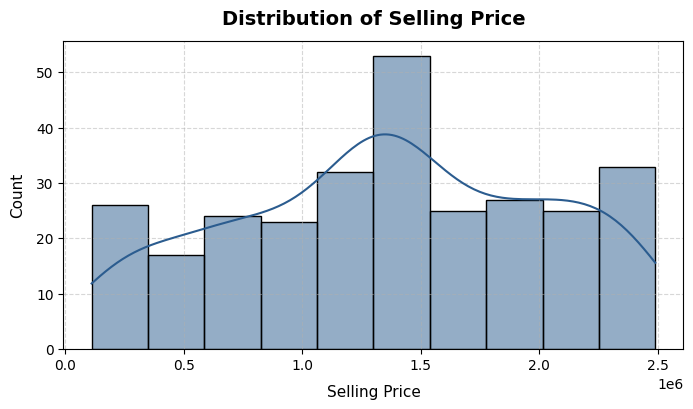

In [ ]:
plt.figure(figsize=(8, 4))
sns.histplot(df['Selling_Price'], kde=True, color='#2b5c8f', edgecolor='black')
plt.title('Distribution of Selling Price', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Selling Price', fontsize=11, labelpad=8)
plt.ylabel('Count', fontsize=11, labelpad=8)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Univariate: Plot boxplot to inspect the spread and outliers of Driven KMs

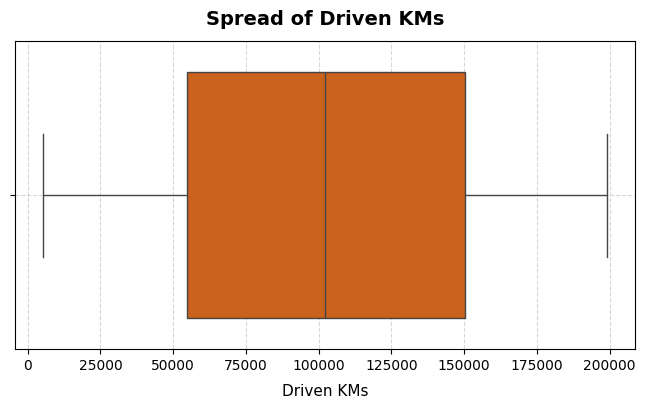

In [ ]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['Driven_KMs'], color='#e65c00', flierprops={'markerfacecolor': 'red'})
plt.title('Spread of Driven KMs', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Driven KMs', fontsize=11, labelpad=8)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Univariate: Plot bar count of cars across different Fuel Types


/tmp/ipykernel_621/766782765.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Fuel_Type', data=df, palette='Set2')


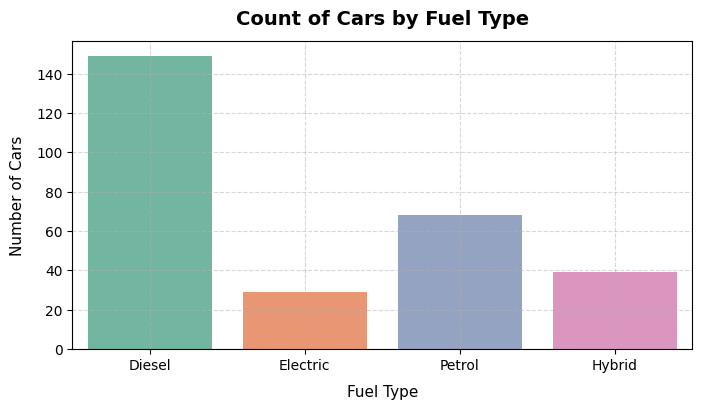

In [ ]:
plt.figure(figsize=(8, 4))
sns.countplot(x='Fuel_Type', data=df, palette='Set2')
plt.title('Count of Cars by Fuel Type', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Fuel Type', fontsize=11, labelpad=8)
plt.ylabel('Number of Cars', fontsize=11, labelpad=8)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


--- Bivariate Analysis ---

 Bivariate: Scatter plot to examine relationship between Driven KMs and Selling Price

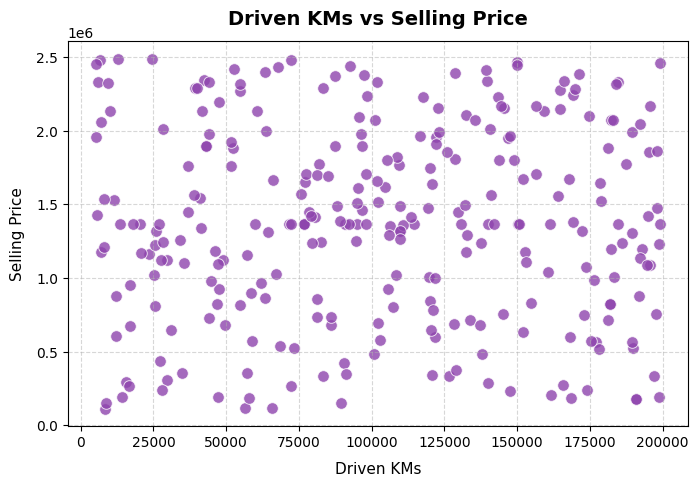

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Driven_KMs', y='Selling_Price', data=df, color='#8e44ad', s=70, alpha=0.8)
plt.title('Driven KMs vs Selling Price', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Driven KMs', fontsize=11, labelpad=8)
plt.ylabel('Selling Price', fontsize=11, labelpad=8)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Bivariate: Box plot to compare Selling Price distribution across car Brands

/tmp/ipykernel_621/4112603501.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Brand', y='Selling_Price', data=df, palette='plasma')


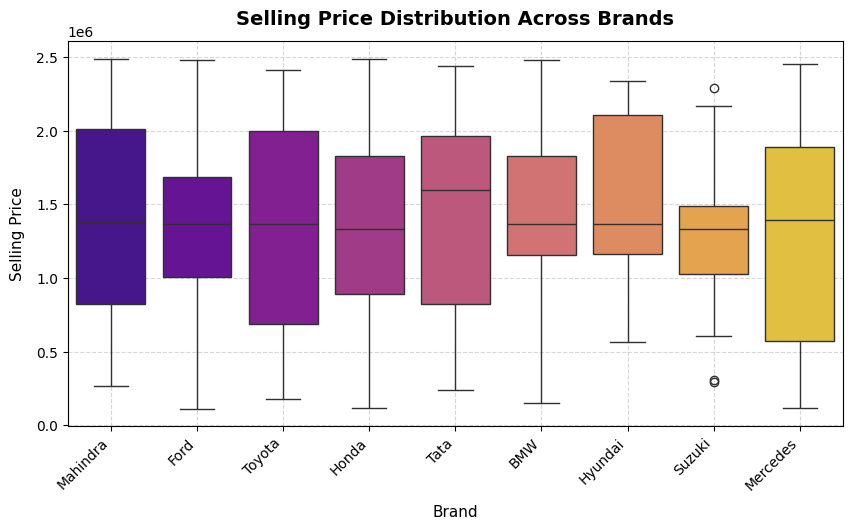

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(x='Brand', y='Selling_Price', data=df, palette='plasma')
plt.xticks(rotation=45, ha='right')
plt.title('Selling Price Distribution Across Brands', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Brand', fontsize=11, labelpad=8)
plt.ylabel('Selling Price', fontsize=11, labelpad=8)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Bivariate: Bar plot to compare average Selling Price by Transmission Type


/tmp/ipykernel_621/2446963653.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Transmission', y='Selling_Price', data=df, palette='viridis', errorbar=None)


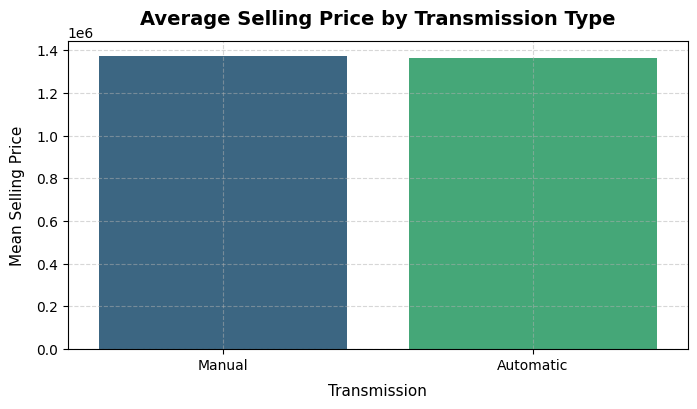

In [ ]:
plt.figure(figsize=(8, 4))
sns.barplot(x='Transmission', y='Selling_Price', data=df, palette='viridis', errorbar=None)
plt.title('Average Selling Price by Transmission Type', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Transmission', fontsize=11, labelpad=8)
plt.ylabel('Mean Selling Price', fontsize=11, labelpad=8)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

--- Multivariate Analysis ---

Multivariate: Correlation heatmap for all numerical features in the dataset

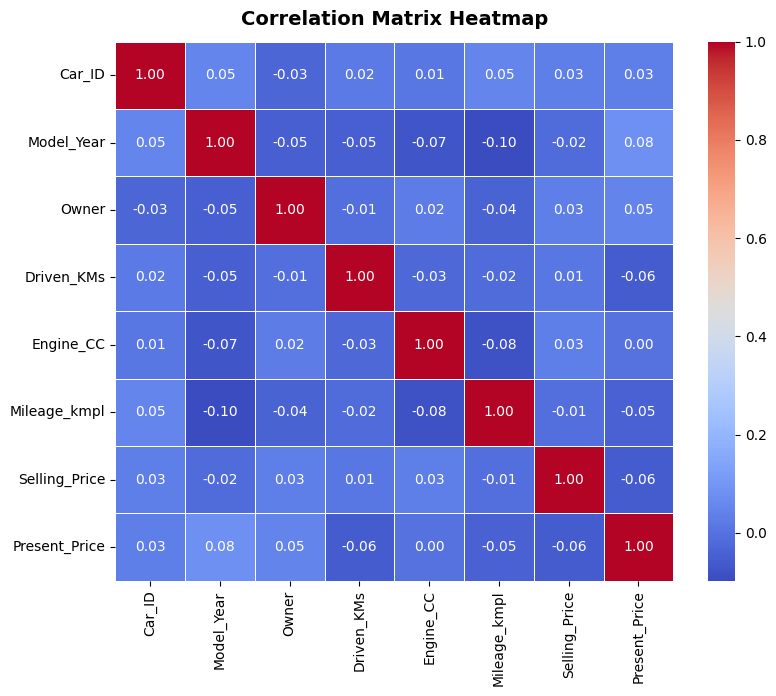

In [ ]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, cbar=True)
plt.title('Correlation Matrix Heatmap', fontsize=14, fontweight='bold', pad=12)
plt.show()

Multivariate: Scatter plot comparing Present Price vs Selling Price colored by Fuel Type

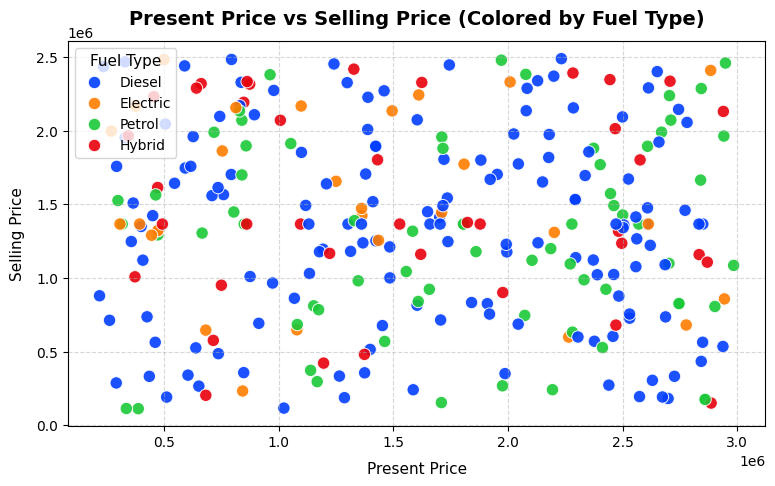

In [ ]:
plt.figure(figsize=(9, 5))
sns.scatterplot(x='Present_Price', y='Selling_Price', hue='Fuel_Type', data=df, palette='bright', s=80, alpha=0.9)
plt.title('Present Price vs Selling Price (Colored by Fuel Type)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Present Price', fontsize=11, labelpad=8)
plt.ylabel('Selling Price', fontsize=11, labelpad=8)
plt.legend(title='Fuel Type', title_fontsize='11', loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Multivariate: Pairplot grid to analyze relationships among key numerical columns

/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:1615: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=x, y=y, **kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:1615: UserWarning: Ignoring `palette` because no `hue` variable has be

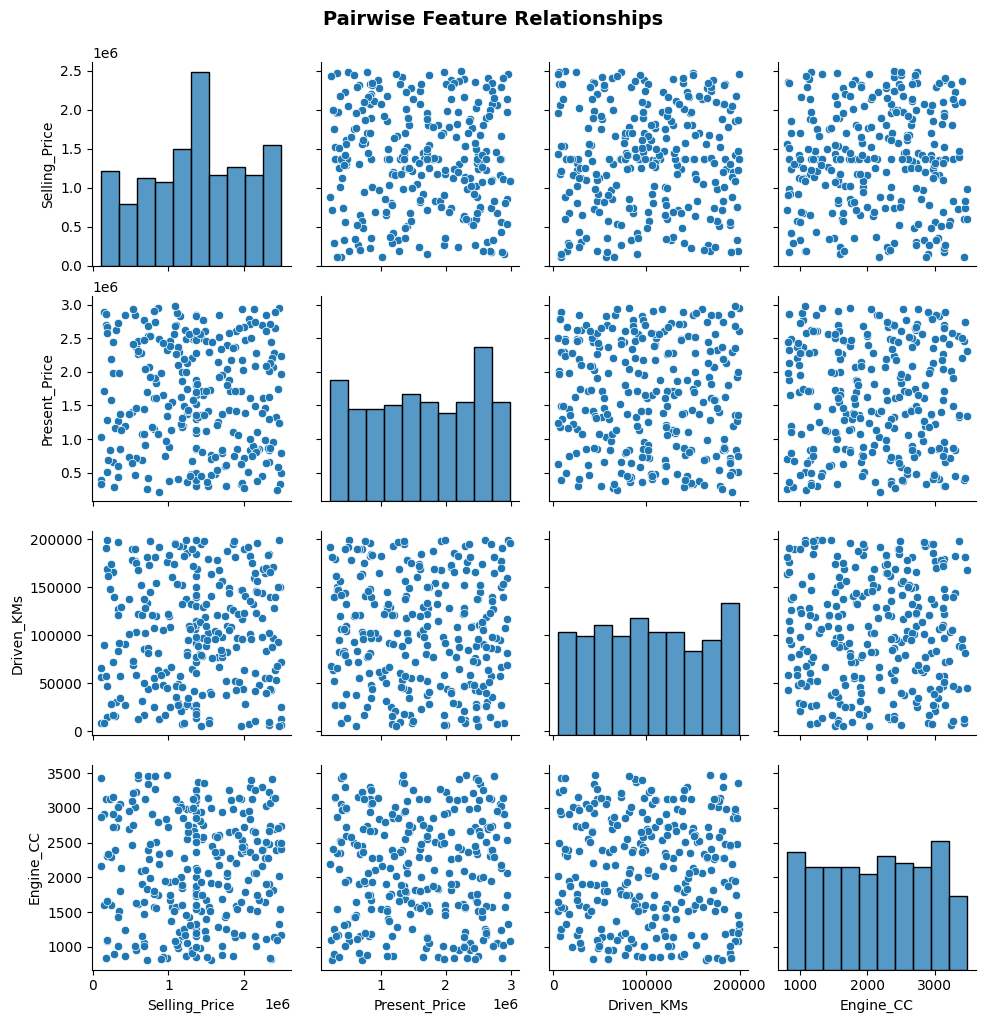

In [ ]:
g = sns.pairplot(df[['Selling_Price', 'Present_Price', 'Driven_KMs', 'Engine_CC']], palette='rocket')
g.fig.suptitle('Pairwise Feature Relationships', y=1.02, fontsize=14, fontweight='bold')
plt.show()








# EDA Final Summary & Business Insights

### 1. Key Resale Drivers
* **Original Cost Impact:** `Present_Price` is the strongest predictor of resale price (`Selling_Price`), displaying a strong positive linear correlation.
* **Brand Prestige:** Premium brands (e.g., Mercedes, BMW) maintain a higher valuation baseline and experience lower percentage-based depreciation compared to mass-market brands.

### 2. Feature & Market Premiums
* **Transmission Premium:** Automatic transmission models systematically command a higher average resale price across all fuel types than manual models.
* **Usage Dynamics:** High odometer readings (`Driven_KMs`) negatively impact resale value as expected, though luxury brand value buffers against sharp usage-based drops.

### 3. Data Hygiene & Modeling Readiness
* **Cleaning & Standardizing:** Resolved categorical inconsistencies across `Brand`, `Fuel_Type`, `Transmission`, `Seller_Type`, and `Owner` columns. Redundant duplicate columns (`Brand_dup`, `Selling_Price_dup`) were dropped.
* **Imputation & Outlier Profile:** Completed mean imputation for missing prices and mode imputation for categorical attributes. Post-cleaning IQR analysis confirms 0 statistical outliers across all numerical columns, rendering the dataset clean and prepared for downstream machine learning tasks.